In [679]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import time


from utils_ML import score_dataset
from utils_preproces import ols_fit, y_distribution_plot, corr_heatmap_plot, make_mi_scores, preprocess_data

from sklearn.ensemble import RandomForestRegressor, VotingRegressor, ExtraTreesRegressor
from xgboost import XGBRegressor, plot_importance
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor


from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold


from scikeras.wrappers import KerasRegressor


from sklearn.metrics import mean_absolute_error

In [680]:
# Set Matplotlib defaults
plt.style.use("seaborn-v0_8-white")
plt.rc("figure", autolayout=True)
plt.rc(
    "axes",
    labelweight="bold",
    labelsize="large",
    titleweight="bold",
    titlesize=14,
    titlepad=10,
)

In [681]:
# Fix random state
random_state = 42

In [682]:
harps = pd.read_csv('harps_sample.csv')
apogee = pd.read_csv('apogee_sample.csv')
galah = pd.read_csv('galah_sample.csv')
gr8 = pd.read_csv('gr8_not_in_harps_sample.csv')

print (f'harps contains {len(harps)} stars')
print (f'apogee contains {len(apogee)} stars')    
print (f'galah contains {len(galah)} stars')
print (f'gr8 contains {len(gr8)} stars')

harps contains 798 stars
apogee contains 108526 stars
galah contains 116050 stars
gr8 contains 1436 stars


In [683]:
apogee = apogee[apogee.parallax >2]
print (len(apogee))
galah = galah[galah.parallax > 3]
print (len(galah))


23511
19678


# Here we focus on getting Fe from no abundance

In [684]:
columns_for_Fe = ['radial_velocity', 'V_lsr',  'U_lsr',  'W_lsr', 'P_gal', # 'parallax',  #'pmra', 'pmdec', #'ra', 'dec',
                'fe_h', ]

apogee = apogee[columns_for_Fe]
harps = harps[columns_for_Fe]
galah = galah[columns_for_Fe]
gr8 = gr8[columns_for_Fe]

In [685]:
def fit_trasform(X):
    X['VW_lsr'] = np.sqrt(X['V_lsr']**2 + X['W_lsr']**2)
    X['UW_lsr'] = np.sqrt(X['U_lsr']**2 + X['W_lsr']**2)
    X['UV_lsr'] = np.sqrt(X['U_lsr']**2 + X['V_lsr']**2)
    X['UVW_lsr'] = np.sqrt(X['U_lsr']**2 + X['V_lsr']**2 + X['W_lsr']**2)
    epsilon = 1e-6
    #log features
    #X['Log_RV'] = np.log(X['RV'] + np.abs(X['RV'].min()))
    X['Log_U_lsr'] = np.log(X['U_lsr'] + np.abs(X['U_lsr'].min()) + epsilon)
    X['Log_V_lsr'] = np.log(X['V_lsr'] + np.abs(X['V_lsr'].min()) + epsilon)
    X['Log_W_lsr'] = np.log(X['W_lsr'] + np.abs(X['W_lsr'].min()) + epsilon)
    X['Log_UW_lsr'] = np.log(X['UW_lsr'])
    X['Log_UVW_lsr'] = np.log(X['UVW_lsr'])

    return X

#apogee = fit_trasform(apogee)
#harps = fit_trasform(harps)
#galah = fit_trasform(galah)
#gr8 = fit_trasform(gr8)

### Identifying and exluding null values

In [686]:
apogee.isnull().sum() # 196 null value for P_gal
apogee.dropna(inplace = True)

In [687]:
galah.isnull().sum() # 1 null value for P_gal
galah.dropna(inplace = True)

In [688]:
#gr8.isnull().sum() # No null values

In [689]:
#harps.isnull().sum() # No null values

### Spliting data into Trianing and Testing sets

In [690]:
# Split APOGEE
apogee_train_full, apogee_test = train_test_split(apogee, test_size=0.1, random_state=random_state)
X_apogee_train = apogee_train_full.drop(columns=['fe_h'])
y_apogee_train = apogee_train_full['fe_h']

X_apogee_test = apogee_test.drop(columns=['fe_h'])
y_apogee_test = apogee_test['fe_h']

# Split GALAH
galah_train_full, galah_test = train_test_split(galah, test_size=0.3, random_state=random_state)
X_galah_train = galah_train_full.drop(columns=['fe_h'])
y_galah_train = galah_train_full['fe_h']

X_galah_test = galah_test.drop(columns=['fe_h'])
y_galah_test = galah_test['fe_h']

# Gr8 no split
X_gr8 = gr8.drop(columns=['fe_h'])
y_gr8 = gr8['fe_h']

# HARPS — no split
X_harps = harps.drop(columns=['fe_h'])
y_harps = harps['fe_h']

# Combine APOGEE and GALAH train sets
X_combined_train = pd.concat([X_apogee_train, X_galah_train, X_gr8], ignore_index=True)
y_combined_train = pd.concat([y_apogee_train, y_galah_train, y_gr8], ignore_index=True)


In [691]:
xgbr = XGBRegressor(random_state=random_state, n_jobs=-1)
lgbr = LGBMRegressor(random_state=random_state, verbosity=-1, n_jobs=-1)



model_names = {
    'xgbr': xgbr,
    'lgbr': lgbr,
}


In [692]:
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.utils.validation import has_fit_parameter

def model_test_CV_models_weighted(X, y, models, k=5, random_state=42):
    kf = KFold(n_splits=k, shuffle=True, random_state=random_state)
    results = {}

    for name, model in models.items():
        print(f"Scoring model: {name}")
        start_time = time.time()
        mae_scores = []

        for train_index, test_index in kf.split(X, y):
            X_train, X_test = X.iloc[train_index], X.iloc[test_index]
            y_train, y_test = y.iloc[train_index], y.iloc[test_index]

            # 1. Compute sample weights based on quantile binning
            n_bins = 20
            kb = KBinsDiscretizer(n_bins=n_bins, encode='ordinal', strategy='quantile')
            y_binned = kb.fit_transform(y_train.values.reshape(-1, 1)).astype(int).flatten()
            bin_counts = np.bincount(y_binned)
            bin_weights = 1 / bin_counts
            sample_weights = bin_weights[y_binned]

            # 2. Special handling for scikeras (DL) model
            if isinstance(model, KerasRegressor):
                model.set_params(model__input_dim=X_train.shape[1])

            # 3. Check if model accepts sample_weight
            if has_fit_parameter(model, "sample_weight"):
                model.fit(X_train, y_train, sample_weight=sample_weights)
            else:
                model.fit(X_train, y_train)

            y_pred = model.predict(X_test)
            mae = mean_absolute_error(y_test, y_pred)
            mae_scores.append(mae)

        elapsed_time = time.time() - start_time
        results[name] = {
            'mean_mae': np.mean(mae_scores),
            'std_mae': np.std(mae_scores),
            'time_sec': elapsed_time
        }

        print(f"{name} done in {elapsed_time:.2f}s → MAE: {results[name]['mean_mae']:.3f} ± {results[name]['std_mae']:.3f}\n")

    return results


In [693]:
baseline_results = model_test_CV_models_weighted(X_gr8, y_gr8, model_names, k=5)

for name, score in baseline_results.items():
    print(f"{name:8s} | MAE: {score['mean_mae']:.3f} ± {score['std_mae']:.3f}")


Scoring model: xgbr
xgbr done in 0.61s → MAE: 0.182 ± 0.007

Scoring model: lgbr
lgbr done in 1.86s → MAE: 0.184 ± 0.009

xgbr     | MAE: 0.182 ± 0.007
lgbr     | MAE: 0.184 ± 0.009


In [694]:
import numpy as np
from sklearn.preprocessing import KBinsDiscretizer

def compute_sample_weights(y, n_bins=10):
    """
    Compute sample weights inversely proportional to frequency in quantile bins.

    Parameters:
        y (Series or ndarray): Target values.
        n_bins (int): Number of quantile bins to split the target into.

    Returns:
        ndarray: Sample weights.
    """
    y = np.asarray(y).reshape(-1, 1)
    kb = KBinsDiscretizer(n_bins=n_bins, encode='ordinal', strategy='quantile')
    y_binned = kb.fit_transform(y).astype(int).flatten()

    bin_counts = np.bincount(y_binned)
    bin_weights = 1.0 / bin_counts
    sample_weights = bin_weights[y_binned]

    return sample_weights


sample_weights = compute_sample_weights(y_combined_train, n_bins=180)

/home/vadibekyan/anaconda3/lib/python3.12/site-packages/sklearn/preprocessing/_discretization.py:307: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 0 are removed. Consider decreasing the number of bins.
  warnings.warn(


In [695]:
from sklearn.utils.validation import has_fit_parameter

def evaluate_on_test_data_weighted(X_train, y_train, test_df, target, models, test_name='Test', sample_weights=None):
    """
    Trains models on the full training set and evaluates on a test set.

    Parameters:
        X_train, y_train: Training features and target.
        test_df: DataFrame containing the test data (including the target column).
        target (str): Name of the target column in test_df.
        models: Dictionary of model_name: model_instance.
        test_name (str): Label for this test set (e.g., 'Apogee', 'HARPS').
        sample_weights: Optional array of sample weights for training.

    Returns:
        dict: model_name → test MAE and baseline MAE
    """
    X_test = test_df.drop(columns=[target])
    y_test = test_df[target]
    results = {}

    for name, model in models.items():
        print(f"Training and evaluating {name} on {test_name}")

        # Handle sample weights if applicable
        if sample_weights is not None and has_fit_parameter(model, "sample_weight"):
            model.fit(X_train, y_train, sample_weight=sample_weights)
        else:
            model.fit(X_train, y_train)

        y_pred = model.predict(X_test)
        mae_model = mean_absolute_error(y_test, y_pred)
        mae_baseline = mean_absolute_error(y_test, [y_test.mean()] * len(y_test))

        results[name] = {
            'mae_model': mae_model,
            'mae_baseline': mae_baseline
        }

        print(f"{name} | {test_name} MAE: {mae_model:.3f} (mean baseline: {mae_baseline:.3f})\n")

    return results


In [696]:
# Try different numbers of bins
bin_range = np.arange(5, 200, 10)
all_results = {}

for n_bins in bin_range:
    print(f"\n>>> Testing n_bins = {n_bins}")
    sample_weights = compute_sample_weights(y_combined_train, n_bins=n_bins)
    results = evaluate_on_test_data_weighted(
        X_train=X_combined_train,
        y_train=y_combined_train,
        test_df=harps,
        target='fe_h',
        models=model_names,
        test_name=f'Test (n_bins={n_bins})',
        sample_weights=sample_weights
    )
    all_results[n_bins] = results



>>> Testing n_bins = 5
Training and evaluating xgbr on Test (n_bins=5)
xgbr | Test (n_bins=5) MAE: 0.194 (mean baseline: 0.204)

Training and evaluating lgbr on Test (n_bins=5)
lgbr | Test (n_bins=5) MAE: 0.170 (mean baseline: 0.204)


>>> Testing n_bins = 15
Training and evaluating xgbr on Test (n_bins=15)
xgbr | Test (n_bins=15) MAE: 0.183 (mean baseline: 0.204)

Training and evaluating lgbr on Test (n_bins=15)
lgbr | Test (n_bins=15) MAE: 0.172 (mean baseline: 0.204)


>>> Testing n_bins = 25
Training and evaluating xgbr on Test (n_bins=25)
xgbr | Test (n_bins=25) MAE: 0.180 (mean baseline: 0.204)

Training and evaluating lgbr on Test (n_bins=25)
lgbr | Test (n_bins=25) MAE: 0.171 (mean baseline: 0.204)


>>> Testing n_bins = 35
Training and evaluating xgbr on Test (n_bins=35)
xgbr | Test (n_bins=35) MAE: 0.178 (mean baseline: 0.204)

Training and evaluating lgbr on Test (n_bins=35)
lgbr | Test (n_bins=35) MAE: 0.171 (mean baseline: 0.204)


>>> Testing n_bins = 45
Training and eva

/home/vadibekyan/anaconda3/lib/python3.12/site-packages/sklearn/preprocessing/_discretization.py:307: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 0 are removed. Consider decreasing the number of bins.
  warnings.warn(


lgbr | Test (n_bins=45) MAE: 0.171 (mean baseline: 0.204)


>>> Testing n_bins = 55
Training and evaluating xgbr on Test (n_bins=55)
xgbr | Test (n_bins=55) MAE: 0.176 (mean baseline: 0.204)

Training and evaluating lgbr on Test (n_bins=55)


/home/vadibekyan/anaconda3/lib/python3.12/site-packages/sklearn/preprocessing/_discretization.py:307: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 0 are removed. Consider decreasing the number of bins.
  warnings.warn(


lgbr | Test (n_bins=55) MAE: 0.171 (mean baseline: 0.204)


>>> Testing n_bins = 65
Training and evaluating xgbr on Test (n_bins=65)
xgbr | Test (n_bins=65) MAE: 0.174 (mean baseline: 0.204)

Training and evaluating lgbr on Test (n_bins=65)


/home/vadibekyan/anaconda3/lib/python3.12/site-packages/sklearn/preprocessing/_discretization.py:307: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 0 are removed. Consider decreasing the number of bins.
  warnings.warn(


... (23 outputs left out)

/home/vadibekyan/anaconda3/lib/python3.12/site-packages/sklearn/preprocessing/_discretization.py:307: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 0 are removed. Consider decreasing the number of bins.
  warnings.warn(


lgbr | Test (n_bins=185) MAE: 0.167 (mean baseline: 0.204)


>>> Testing n_bins = 195
Training and evaluating xgbr on Test (n_bins=195)
xgbr | Test (n_bins=195) MAE: 0.169 (mean baseline: 0.204)

Training and evaluating lgbr on Test (n_bins=195)


/home/vadibekyan/anaconda3/lib/python3.12/site-packages/sklearn/preprocessing/_discretization.py:307: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 0 are removed. Consider decreasing the number of bins.
  warnings.warn(
/tmp/ipykernel_17477/278489637.py:20: RuntimeWarning: divide by zero encountered in divide
  bin_weights = 1.0 / bin_counts


lgbr | Test (n_bins=195) MAE: 0.168 (mean baseline: 0.204)



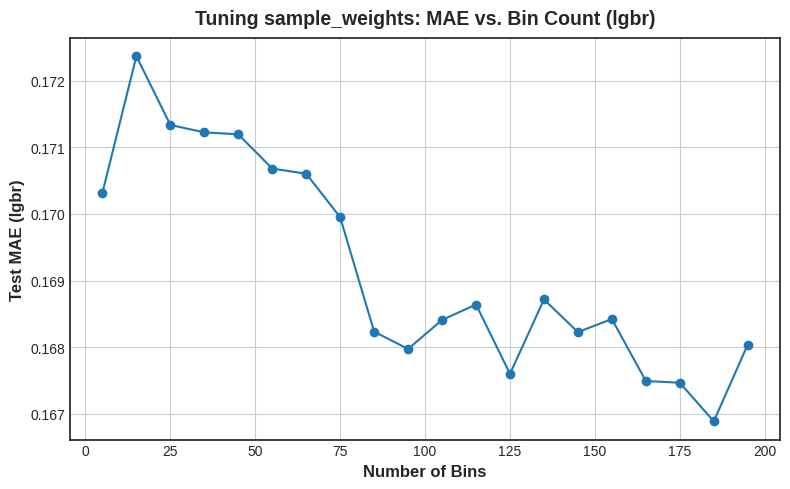

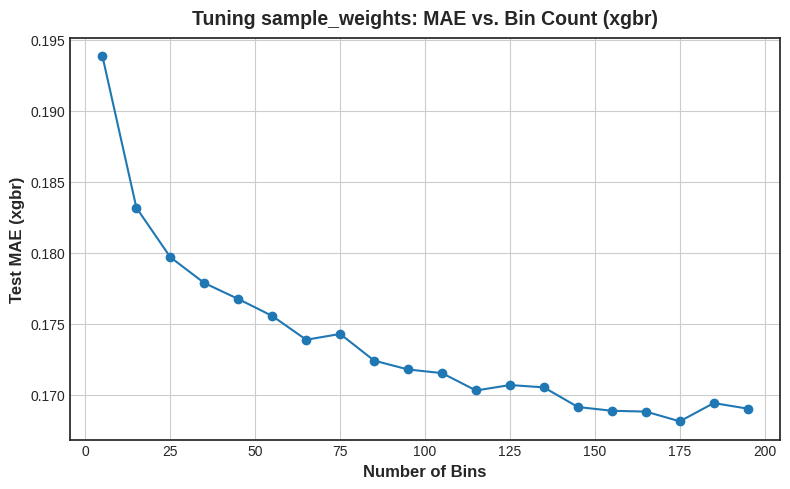

In [697]:
def plot_mae_vs_bins(all_results, model_name='lgbr', bin_range=None):
    """
    Plot test MAE as a function of number of bins used for sample weighting.

    Parameters:
        all_results (dict): Nested dictionary {n_bins: {model_name: {mae_model: ...}}}
        model_name (str): Name of the model to evaluate (e.g., 'lgbr')
        bin_range (list): List of bin counts to plot (keys in all_results)
    """
    if bin_range is None:
        bin_range = sorted(all_results.keys())

    maes = [all_results[n]['{}'.format(model_name)]['mae_model'] for n in bin_range]

    plt.figure(figsize=(8, 5))
    plt.plot(bin_range, maes, marker='o')
    plt.xlabel("Number of Bins")
    plt.ylabel(f"Test MAE ({model_name})")
    plt.title(f"Tuning sample_weights: MAE vs. Bin Count ({model_name})")
    plt.grid(True)
    plt.tight_layout()
    plt.show()


plot_mae_vs_bins(all_results, model_name='lgbr', bin_range=None)
plot_mae_vs_bins(all_results, model_name='xgbr', bin_range=None)

In [698]:
def evaluate_on_test_data(X_train, y_train, test_df, target, models, test_name='Test'):
    """
    Trains models on the full training set and evaluates on a test set.

    Parameters:
        X_train, y_train: Training features and target.
        test_df: DataFrame containing the test data (including the target column).
        target (str): Name of the target column in test_df.
        models: Dictionary of model_name: model_instance.
        test_name (str): Label for this test set (e.g., 'Apogee', 'HARPS').

    Returns:
        dict: model_name → test MAE and baseline MAE
    """
    X_test = test_df.drop(columns=[target])
    y_test = test_df[target]

    results = {}

    for name, model in models.items():
        print(f"Training and evaluating {name} on {test_name}")
        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)

        mae_model = mean_absolute_error(y_test, y_pred)
        mae_baseline = mean_absolute_error(y_test, [y_test.mean()] * len(y_test))

        results[name] = {
            'mae_model': mae_model,
            'mae_baseline': mae_baseline
        }

        print(f"{name} | {test_name} MAE: {mae_model:.3f} (mean baseline: {mae_baseline:.3f})\n")

    return results


In [699]:
# Evaluate on Apogee test
results_apogee_weighted = evaluate_on_test_data_weighted(
    X_combined_train, y_combined_train,
    test_df=apogee_test,
    target='fe_h',
    models=model_names,
    test_name='Apogee',
    sample_weights=sample_weights,
)

# Evaluate on HARPS test
results_harps_weighted = evaluate_on_test_data_weighted(
    X_combined_train, y_combined_train,
    test_df=harps,
    target='fe_h',
    models=model_names,
    test_name='HARPS',
    sample_weights=sample_weights,
)

# Evaluate on GALAH test
results_galah_weighted = evaluate_on_test_data_weighted(
    X_combined_train, y_combined_train,
    test_df=galah,
    target='fe_h',
    models=model_names,
    test_name='GALAH',
    sample_weights=sample_weights,
)

Training and evaluating xgbr on Apogee
xgbr | Apogee MAE: 0.141 (mean baseline: 0.145)

Training and evaluating lgbr on Apogee
lgbr | Apogee MAE: 0.140 (mean baseline: 0.145)

Training and evaluating xgbr on HARPS
xgbr | HARPS MAE: 0.169 (mean baseline: 0.204)

Training and evaluating lgbr on HARPS
lgbr | HARPS MAE: 0.168 (mean baseline: 0.204)

Training and evaluating xgbr on GALAH
xgbr | GALAH MAE: 0.142 (mean baseline: 0.148)

Training and evaluating lgbr on GALAH
lgbr | GALAH MAE: 0.139 (mean baseline: 0.148)



In [700]:
# Evaluate on Apogee test
results_apogee = evaluate_on_test_data(
    X_combined_train, y_combined_train,
    test_df=apogee_test,
    target='fe_h',
    models=model_names,
    test_name='Apogee'
)

# Evaluate on HARPS test
results_harps = evaluate_on_test_data(
    X_combined_train, y_combined_train,
    test_df=harps,
    target='fe_h',
    models=model_names,
    test_name='HARPS'
)

# Evaluate on GALAH test
results_galah = evaluate_on_test_data(
    X_combined_train, y_combined_train,
    test_df=galah,
    target='fe_h',
    models=model_names,
    test_name='GALAH'
)

Training and evaluating xgbr on Apogee
xgbr | Apogee MAE: 0.139 (mean baseline: 0.145)

Training and evaluating lgbr on Apogee
lgbr | Apogee MAE: 0.135 (mean baseline: 0.145)

Training and evaluating xgbr on HARPS
xgbr | HARPS MAE: 0.174 (mean baseline: 0.204)

Training and evaluating lgbr on HARPS
lgbr | HARPS MAE: 0.172 (mean baseline: 0.204)

Training and evaluating xgbr on GALAH
xgbr | GALAH MAE: 0.126 (mean baseline: 0.148)

Training and evaluating lgbr on GALAH
lgbr | GALAH MAE: 0.135 (mean baseline: 0.148)



In [701]:
import matplotlib.pyplot as plt
import numpy as np

def plot_residuals_vs_true(y_true, y_pred, model_name='Model', sample_name='Test Set'):
    """
    Plot residuals (y_true - y_pred) vs y_true, and residuals from predicting the mean.

    Parameters:
        y_true: Ground truth target values.
        y_pred: Model predictions.
        model_name: Name of the model for labeling.
        sample_name: Name of the dataset (e.g., 'Apogee' or 'HARPS').
    """
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_mean = np.full_like(y_true, y_true.mean())

    residuals_model = y_true - y_pred
    residuals_mean = y_true - y_mean

    plt.figure(figsize=(10, 6))
    plt.scatter(y_true, residuals_model, alpha=0.6, label=f'{model_name}', s=20)
    plt.scatter(y_true, residuals_mean, alpha=0.4, label='Mean predictor', s=20, marker='x')

    plt.axhline(0, color='gray', linestyle='--')
    plt.xlabel('True Value (y)')
    plt.ylabel('Residual (y_true - y_pred)')
    plt.title(f'Residuals vs True Values ({sample_name})')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


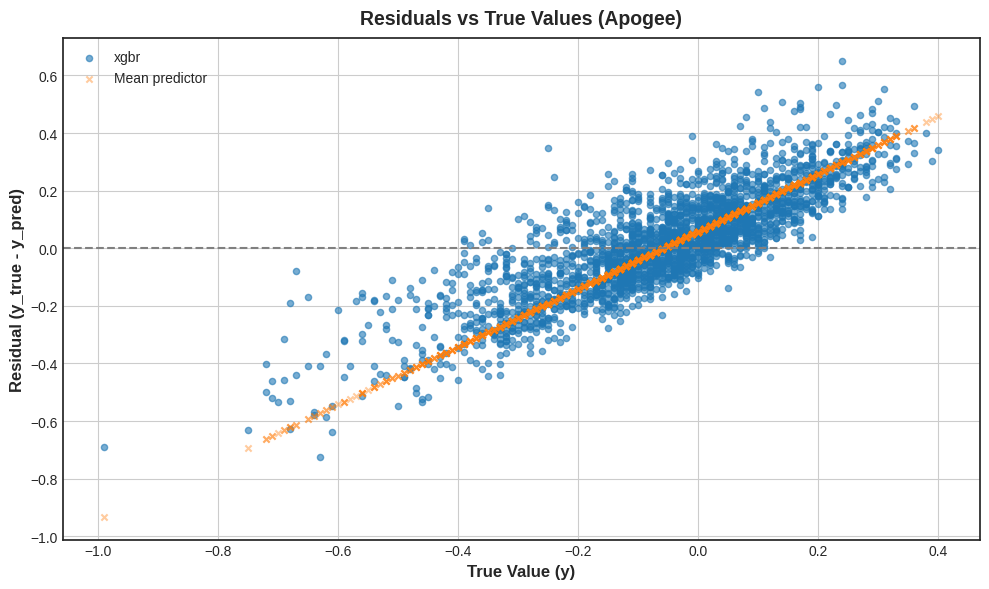

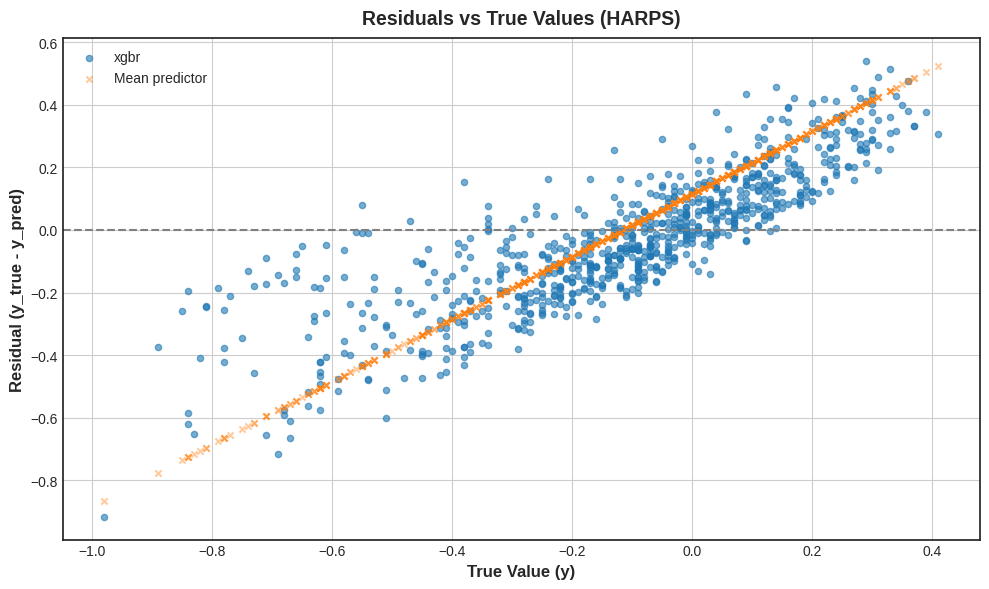

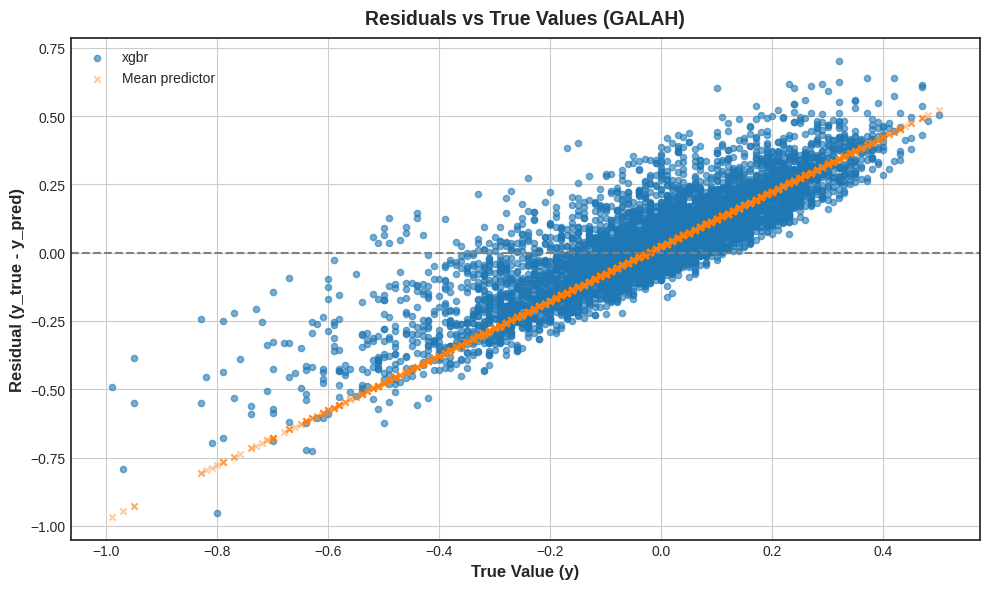

In [702]:
# Example for one model and one test set
best_model_name = 'xgbr'
model = model_names[best_model_name]
model.fit(X_combined_train, y_combined_train, sample_weight=sample_weights)

y_pred_apogee = model.predict(X_apogee_test)
plot_residuals_vs_true(y_apogee_test, y_pred_apogee, model_name=best_model_name, sample_name='Apogee')

y_pred_harps = model.predict(X_harps)
plot_residuals_vs_true(y_harps, y_pred_harps, model_name=best_model_name, sample_name='HARPS')

y_pred_galah = model.predict(X_galah_test)
plot_residuals_vs_true(y_galah_test, y_pred_galah, model_name=best_model_name, sample_name='GALAH')
